In [1]:
!pip install -U datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 7.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 46.6 MB/s  0:00:01
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [datasets]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
from datasets import load_dataset

df = load_dataset("microsoft/cats_vs_dogs", split= 'train')

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

In [3]:
df= df.train_test_split(test_size= 0.2, shuffle= True, stratify_by_column='labels')

In [4]:
dfTrain, dfTest= df['train'], df['test']

0


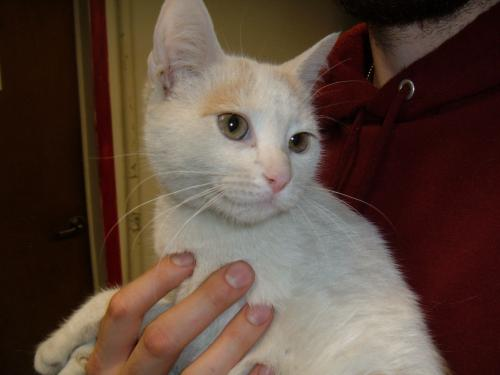

In [5]:
print(dfTrain[0]['labels'])
dfTrain[0]['image']

1


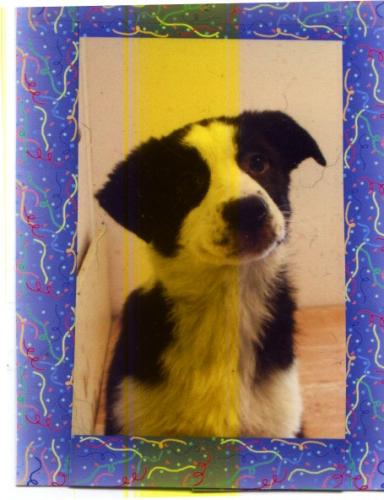

In [6]:
print(dfTrain[1]['labels'])
dfTrain[1]['image']

The question is "Is this a dog? "

Creating Dataset

In [7]:
import datasets
from torch.utils.data import Dataset
from torchvision import transforms

class CatDogDataset(Dataset):
    '''
        This is our custome dataset.
    '''
    def __init__(self,
                 data: datasets.Dataset,
                 transform: transforms= None
                 )-> None:
        self.data= data
        self.transform= transform

    def __len__(self)-> int:
        return len(self.data)

    def __getitem__(self, idx)-> dict:
        image= self.data[idx]['image']
        label= self.data[idx]['labels']
        image= image.convert('RGB')

        if self.transform:
            image= self.transform(image)
        return image, label

In [8]:
from torchvision.transforms import ToTensor, Compose, Resize

train= CatDogDataset(dfTrain,
                       Compose([Resize((224, 224)), ToTensor()]))

test= CatDogDataset(dfTest,
                    Compose([Resize((224, 224)), ToTensor()]))

Creating DataLoader

In [9]:
from torch.utils.data import DataLoader

TrainLoader = DataLoader(
    train,
    batch_size=64,
    shuffle=True
)

TestLoader= DataLoader(
    test,
    batch_size=64,
    shuffle=True
)

In [10]:
next(iter(TrainLoader))[1]

tensor([0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1,
        0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1,
        0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0])

Creating the CNN

In [11]:
import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features= nn.Sequential(

            nn.Conv2d(3, 32, kernel_size= 3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2),

            nn.Conv2d(32, 64, kernel_size= 3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2),

            nn.Conv2d(64, 128, kernel_size= 3, padding= 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size= 2),
        )

        self.classifier= nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x= self.features(x)
        x= self.classifier(x)
        return x

In [12]:
model = CNN()

dummy_input = torch.randn(32, 3, 224, 224)

output = model(dummy_input)

output

tensor([[ 0.0307, -0.1232],
        [ 0.0300, -0.1227],
        [ 0.0291, -0.1235],
        [ 0.0304, -0.1217],
        [ 0.0303, -0.1220],
        [ 0.0304, -0.1223],
        [ 0.0298, -0.1239],
        [ 0.0296, -0.1221],
        [ 0.0303, -0.1233],
        [ 0.0284, -0.1223],
        [ 0.0276, -0.1225],
        [ 0.0296, -0.1217],
        [ 0.0305, -0.1212],
        [ 0.0284, -0.1226],
        [ 0.0299, -0.1231],
        [ 0.0298, -0.1227],
        [ 0.0287, -0.1203],
        [ 0.0293, -0.1239],
        [ 0.0294, -0.1229],
        [ 0.0285, -0.1219],
        [ 0.0304, -0.1219],
        [ 0.0297, -0.1232],
        [ 0.0305, -0.1220],
        [ 0.0288, -0.1216],
        [ 0.0295, -0.1203],
        [ 0.0284, -0.1219],
        [ 0.0296, -0.1214],
        [ 0.0301, -0.1218],
        [ 0.0288, -0.1228],
        [ 0.0301, -0.1229],
        [ 0.0302, -0.1222],
        [ 0.0302, -0.1227]], grad_fn=<AddmmBackward0>)

# The training loop

In [13]:
model = CNN()
optim= torch.optim.Adam(model.parameters(), lr= 0.001)
critertion= nn.CrossEntropyLoss()

In [14]:
from tqdm import tqdm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

epochs = 30

for epoch in range(epochs):
    model.train()
    RunningLoss = 0.0

    for batch in tqdm(TrainLoader, desc=f"Epoch {epoch+1}/{epochs}", leave=False):
        images, labels = batch

        images = images.to(device)
        labels = labels.to(device)

        optim.zero_grad()  # clear the board
        output = model(images) # answer the test
        loss = critertion(output, labels) # grade the test
        loss.to(device)
        loss.backward() # give review
        optim.step() # learn the lesson

        RunningLoss += loss.item()

    EpochLoss = RunningLoss / len(TrainLoader)
    print(f"Epoch: {epoch+1}/{epochs}, Loss: {EpochLoss:.4f}")

Epoch: 1/30, Loss: 0.6726


Epoch: 2/30, Loss: 0.6448


Epoch: 3/30, Loss: 0.6311


Epoch: 4/30, Loss: 0.6097


Epoch: 5/30, Loss: 0.5819


Epoch: 6/30, Loss: 0.5741


... (20 outputs left out)

Epoch: 27/30, Loss: 0.4428


Epoch: 28/30, Loss: 0.4354


Epoch: 29/30, Loss: 0.4334


Epoch: 30/30, Loss: 0.4273


# Evaluation

In [15]:
correct, total= 0, 0
model.eval()
with torch.no_grad():
    for batch in tqdm(TestLoader):
        images, labels= batch
        images= images.to(device)
        labels= labels.to(device)
        output= model(images)
        predections= output.argmax(dim= 1)
        total+= labels.size(0)
        correct+= (predections == labels).sum().item()

print(f"Accuracy: {100 * correct / total:.2f}%")

100%|██████████| 74/74 [00:27<00:00,  2.73it/s]

Accuracy: 79.56%


# Let's understand the model better

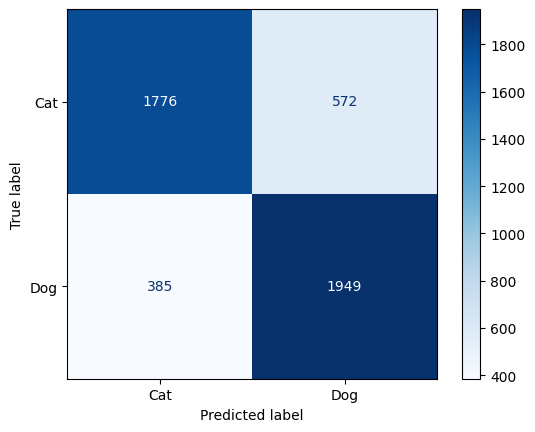

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for batch in TestLoader:

        images, labels = batch
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Cat', 'Dog']
)

disp.plot(cmap='Blues')
plt.show()

In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=['Cat', 'Dog']
    )
)

              precision    recall  f1-score   support

         Cat       0.82      0.76      0.79      2348
         Dog       0.77      0.84      0.80      2334

    accuracy                           0.80      4682
   macro avg       0.80      0.80      0.80      4682
weighted avg       0.80      0.80      0.80      4682



# Saving the model for production

In [19]:
torch.save(model.state_dict(), "model.pt")